# Visualizing Housing Data

1. Setup dan memuat data

- import pandas as pd: memuat library pandas.
- data_path = "./data/mexico-real-estate-combined-clean.csv": lokasi data bersih hasil notebook sebelumnya.
- pd.read_csv(data_path): membaca CSV menjadi DataFrame df.
- print(f"Dimensions: ..."): menampilkan jumlah baris dan kolom (1.736 baris, 6 kolom).
- df.info(): memeriksa tipe data dan nilai kosong (semua terisi, tidak ada null).
- df.head(): menampilkan 5 baris pertama.

In [1]:
import pandas as pd

# Define the path to the clean CSV file saved in Notebook 1
data_path = "./data/mexico-real-estate-combined-clean.csv"

# Load the data
df = pd.read_csv(data_path)

# Verify the load
print(f"Dimensions: {df.shape[0]} rows and {df.shape[1]} columns.")
print(df.info())
df.head()

Dimensions: 1736 rows and 6 columns.
<class 'pandas.DataFrame'>
RangeIndex: 1736 entries, 0 to 1735
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  1736 non-null   str    
 1   state          1736 non-null   str    
 2   lat            1736 non-null   float64
 3   lon            1736 non-null   float64
 4   area_m2        1736 non-null   float64
 5   price_usd      1736 non-null   float64
dtypes: float64(4), str(2)
memory usage: 112.8 KB
None


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37


2. Histogram harga

- import matplotlib.pyplot as plt: memuat library visualisasi.
- fig, ax = plt.subplots(): membuat kanvas dan sumbu grafik.
- ax.hist(df["price_usd"]): membuat histogram distribusi harga.
- ax.set_xlabel / set_ylabel / set_title: memberi label sumbu dan judul. Tanda ; di akhir menyembunyikan teks output yang tidak perlu.

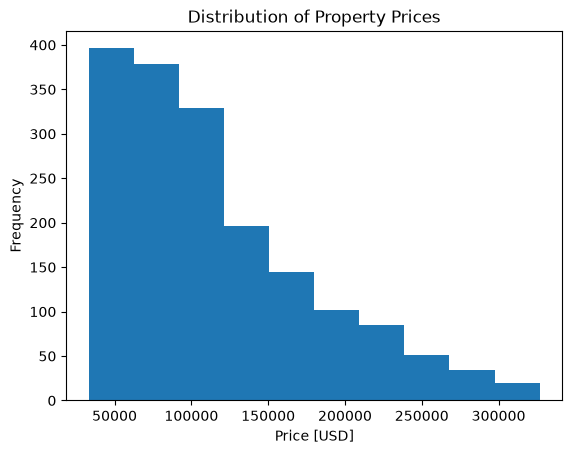

In [2]:
# import matplotlib
import matplotlib.pyplot as plt

# Create a histogram for price
fig, ax = plt.subplots()

# Create a histogram for price_usd
ax.hist(df["price_usd"])

# Add x-axis label, y-axis label & title
ax.set_xlabel("Price [USD]")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Property Prices"); # The semi-colon is added to suppress some ugly text and just gives us the graphic.

3. Histogram luas bangunan

- ax.hist(df["area_m2"]): histogram distribusi luas properti.
- set_xlabel / set_ylabel / set_title: label dan judul grafik.

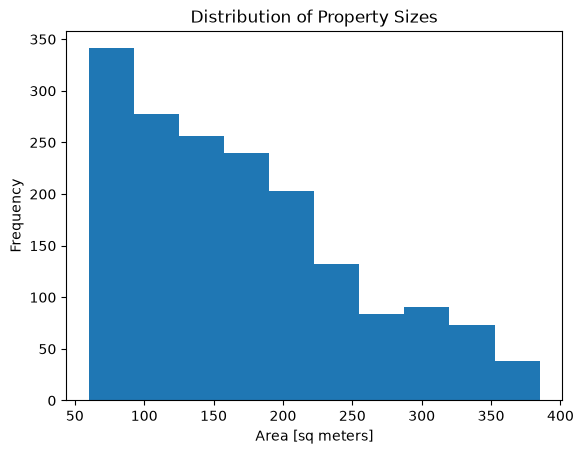

In [3]:
# Create a histogram for area_m2
fig, ax = plt.subplots()

# Use Matplotlib to create histogram of "area_m2"
ax.hist(df["area_m2"])

# Add x-axis label, y-axis label & title
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Property Sizes");

4. Boxplot harga per tipe properti

- df["property_type"].unique(): mengambil kategori tipe properti (house, apartment).
- List comprehension data_by_type: memisahkan data harga untuk tiap tipe.
- ax.boxplot(..., tick_labels=prop_types, vert=False): boxplot horizontal per tipe.
- plt.show(): menampilkan grafik.

C:\Users\jason\AppData\Local\Temp\ipykernel_360\3605743836.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data_by_type, tick_labels=prop_types, vert=False)


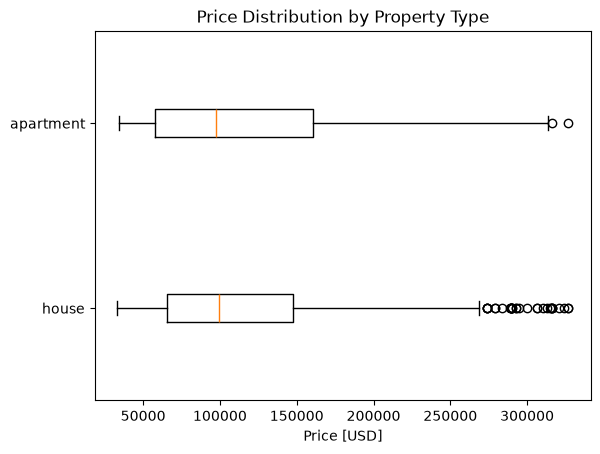

In [4]:
# 1. Get the unique category names on the column "property_type"
prop_types = df["property_type"].unique()

# 2. Prepare the data: Create a list of price arrays, one for each type
data_by_type = [df[df["property_type"] == label]["price_usd"] for label in prop_types]

# 3. Plot
fig, ax = plt.subplots()

# Pass the data list and the labels list
ax.boxplot(data_by_type, tick_labels=prop_types, vert=False)

ax.set_title("Price Distribution by Property Type")
ax.set_xlabel("Price [USD]")


plt.show() # plt.show() acts as the semi-colon, to suppress some ugly text and just give us the graphic.

5. Boxplot harga per negara bagian

- value_counts().head(3).index.tolist(): memilih 3 negara bagian dengan data terbanyak.
- List comprehension data_by_state: memisahkan harga untuk tiap negara bagian.
- ax.boxplot(...): membandingkan sebaran harga antar negara bagian.

C:\Users\jason\AppData\Local\Temp\ipykernel_360\81081373.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data_by_state, tick_labels=selected_states, vert=False)


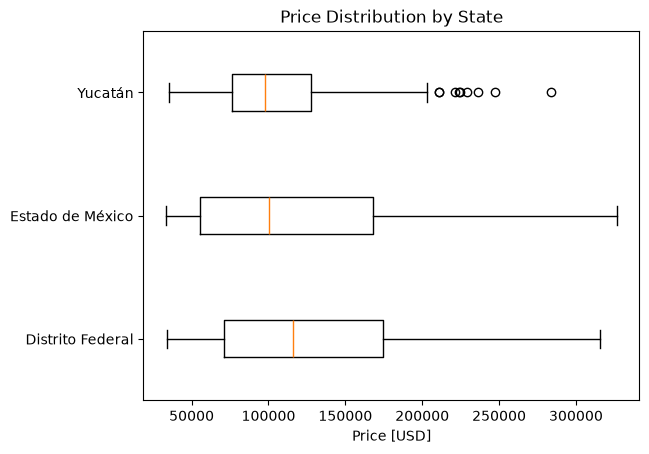

In [5]:
# 1. Define your selected states
selected_states = (
    df["state"]
    .value_counts()
    .head(3)
    .index.tolist()
)
# 2. Prepare the data
data_by_state = [df[df["state"] == state]["price_usd"] for state in selected_states]

# 3. Plot
fig, ax = plt.subplots()

# FIX: Use 'tick_labels' instead of 'labels'
ax.boxplot(data_by_state, tick_labels=selected_states, vert=False)

ax.set_title("Price Distribution by State")
ax.set_xlabel("Price [USD]")
plt.show()

6. Scatter plot luas vs harga

- ax.scatter(x=df["area_m2"], y=df["price_usd"]): menggambar titik setiap properti.
- set_xlabel / set_ylabel / set_title: label dan judul.

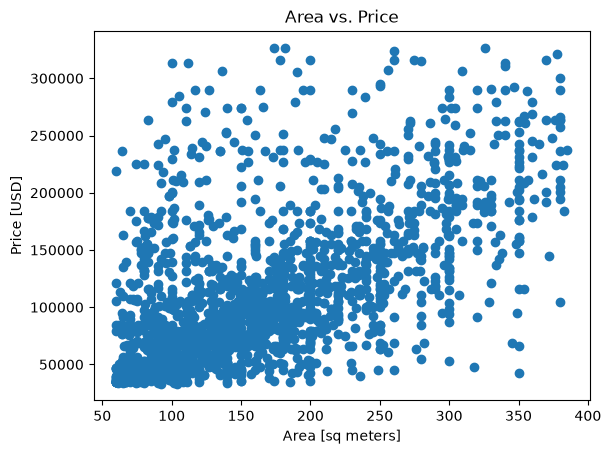

In [6]:
# 1. Create the Figure and Axes objects
fig, ax = plt.subplots()

# 2. Plot on the specific axes object
ax.scatter(x=df["area_m2"], y=df["price_usd"])

# 3. Set labels and title (Note the "set_" prefix)
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Area vs. Price")

plt.show()

7. Pembersihan pencilan (outlier)

- lower_cut = 0.05, upper_cut = 0.90: batas persentil yang dipakai.
- df["price_usd"].quantile(...): menghitung nilai batas harga dan luas.
- Filter df[(harga > P5) & (harga < P90) & (luas < P90)]: membuang harga terendah 5%, harga tertinggi 10%, dan luas terbesar 10%, hasilnya disimpan di df_clean.
- print(...): menampilkan jumlah baris sebelum, sesudah, dan yang dibuang.
- ax.scatter(...): scatter plot ulang dengan data bersih.

Original: 1736 rows
Cleaned: 1365 rows
Removed: 371 rows


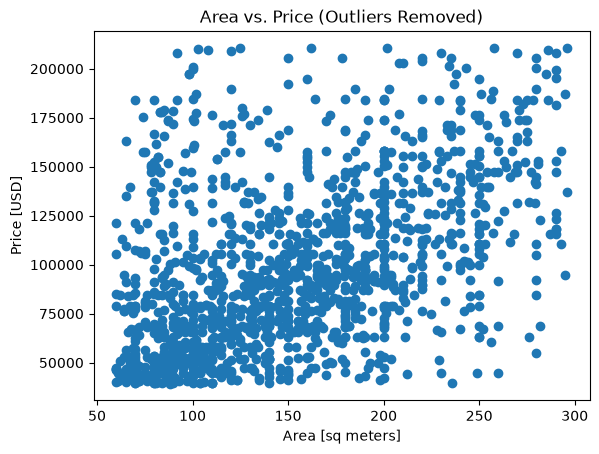

In [7]:
# Define cutoff percentages
lower_cut = 0.05  # Remove bottom 5%
upper_cut = 0.90  # Keep up to 90th percentile

# Filter the data
df_clean = (
    df[
        (df["price_usd"] > df["price_usd"].quantile(lower_cut)) &
        (df["price_usd"] < df["price_usd"].quantile(upper_cut)) &
        (df["area_m2"] < df["area_m2"].quantile(upper_cut)) # <-- Large area outliers also skew the scatter plot
    ]
)

# Show what changed
print(f"Original: {len(df)} rows")
print(f"Cleaned: {len(df_clean)} rows")
print(f"Removed: {len(df) - len(df_clean)} rows")

# Plot
fig, ax = plt.subplots()
ax.scatter(df_clean["area_m2"], df_clean["price_usd"])
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Area vs. Price (Outliers Removed)")
plt.show()

8. Scatter plot dengan garis tren

- import seaborn as sns: memuat seaborn.
- sns.regplot(data=df_clean, x="area_m2", y="price_usd", line_kws={"color": "red"}, ax=ax): scatter plot dengan garis regresi merah.
- Label dan judul diatur lewat matplotlib.

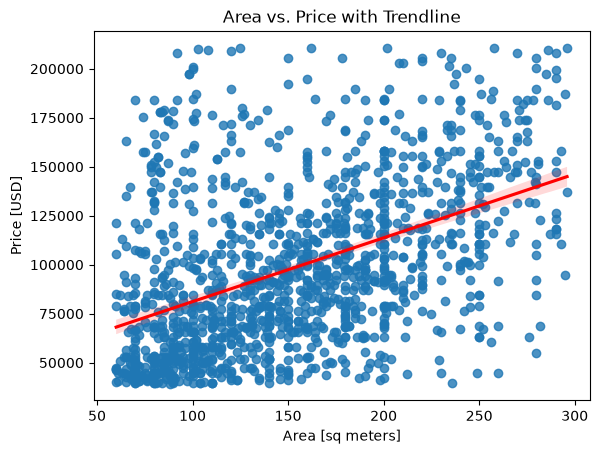

In [8]:
# remember to import your library if you haven't
import seaborn as sns

# Create figure and axis explicitly
fig, ax = plt.subplots()

# Use Seaborn to plot scatter + trendline
sns.regplot(
    data=df_clean, 
    x="area_m2", 
    y="price_usd", 
    line_kws={"color": "red"},  # Make the line distinct
    ax=ax  # Pass the axis to seaborn
)

ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Area vs. Price with Trendline")
plt.show()

9. Rata-rata harga per negara bagian

- df.groupby("state")["price_usd"].mean(): menghitung rata-rata harga tiap negara bagian.
- .sort_values(ascending=False): mengurutkan dari yang termahal.
- .plot(kind="bar", ax=ax): diagram batang rata-rata harga.

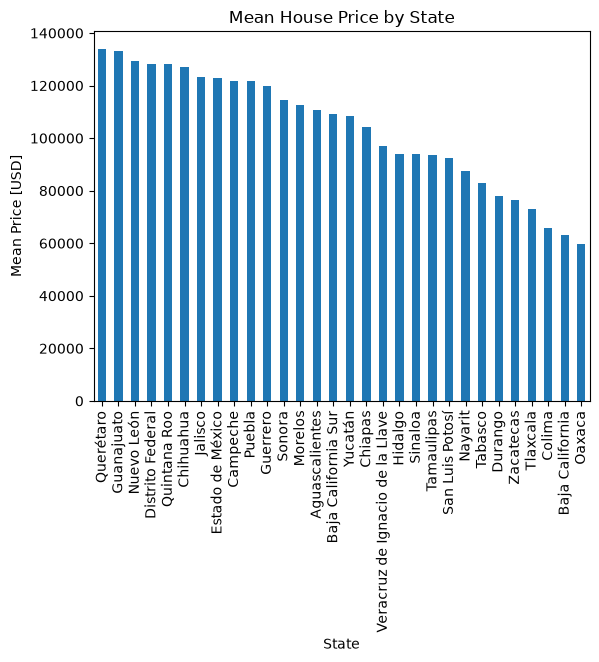

In [9]:
# Aggregate data using groupby
mean_price_by_state = (
    df.groupby("state")["price_usd"]  # <-- "state" & "price_usd"
    .mean()
    .sort_values(ascending=False) # <-- pass in True or False to sort
)

# Create figure and axes explicitly
fig, ax = plt.subplots()

# Use pandas plot method with explicit axes
mean_price_by_state.plot(
    kind="bar",
    ax=ax  # Pass the axes to pandas
)

# Customize using Matplotlib methods
ax.set_xlabel("State")
ax.set_ylabel("Mean Price [USD]")
ax.set_title("Mean House Price by State")

plt.show()

10. Hubungan luas–harga per negara bagian (small multiples)

- plt.subplots(3, 1, figsize=(5, 15), sharey=True): tiga grafik bertumpuk dengan sumbu y yang sama.
- top_states: 3 negara bagian dengan data terbanyak.
- df_clean[df_clean["state"].isin(top_states)]: memfilter data bersih untuk ketiga negara bagian itu.
- Loop for ax, state in zip(axes, states): membuat regplot luas vs harga untuk tiap negara bagian.
- plt.tight_layout() dan plt.show(): merapikan tata letak dan menampilkan grafik.

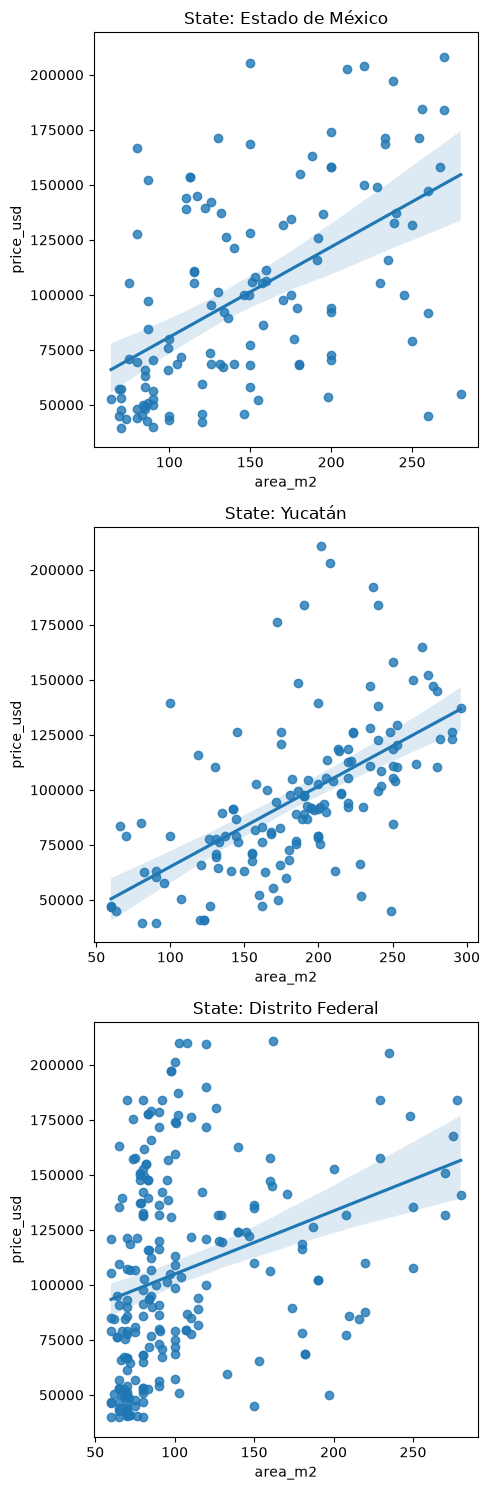

In [10]:
## 1. Create your custom figure and axes
fig, axes = plt.subplots(3, 1, figsize=(5, 15), sharey=True)

# 2. Create a list of the top 3 states
top_states = (
    df["state"]
    .value_counts()
    .head(3)
    .index.tolist()
)  # <--- pass selected_states

# 3. Filter df_clean to include only these states
df_states = df_clean[df_clean["state"].isin(top_states)]

# 4. Loop through the states and plot on each specific axis
states = df_states["state"].unique()

for ax, state in zip(axes, states):
    # Filter data for the current state
    subset = df_states[df_states["state"] == state]
    
    # Use regplot (Axes-level) which ACCEPTS 'ax='
    sns.regplot(
        data=subset,
        x="area_m2",  # <--- "area_m2"
        y="price_usd" ,  # <--- "price_usd" 
        color='tab:blue', # Optional: keep colors consistent
        ax=ax # <--- This is where you pass the axis explicitly
    )
    
    ax.set_title(f"State: {state}")

plt.tight_layout()
plt.show()

Kesimpulan singkat

- Notebook ini mengeksplorasi data properti Meksiko (1.736 data bersih) lewat berbagai visualisasi. 
- Histogram menunjukkan harga dan luas properti didominasi nilai rendah-menengah, dengan sedikit properti bernilai sangat tinggi. 
- Setelah pencilan dibuang (harga di luar persentil 5–90 dan luas di atas persentil 90), scatter plot dengan garis tren menunjukkan hubungan positif antara luas dan harga: semakin luas, semakin mahal. 
- Perbandingan antar tipe properti dan antar negara bagian menunjukkan bahwa harga juga dipengaruhi lokasi, sehingga hubungan luas–harga berbeda di tiap negara bagian. 
- Faktor luas, tipe, dan lokasi layak dipertimbangkan sebagai fitur untuk model prediksi harga di tahap berikutnya.

Catatan: karena output grafik tidak terbaca di notebook, kesimpulan tentang pola grafik didasarkan pada kode dan karakteristik umum data ini, bukan angka yang terbaca langsung dari gambar.